In [1]:
using Flux
using CUDA, cuDNN
using StatsPlots
using Plots;
default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging;
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras

In [2]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu

    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end

    CUDA.allowscalar(false)  # recommended
end

┌ Info: 🚀 Functional GPU detected! Setting device to CUDA.
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W1sdnNjb2RlLXJlbW90ZQ==.jl:6


One dimensional convolution expects data of dimension $748 \times 1\times B$. We introduce this dummy dimension to the data.

In [90]:
include("./utils.jl")
include("./io_utils.jl")
batch_size = 64
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor_shape=(28^2, 1, :))

# mnist_binary_test_loader = Flux.DataLoader((mnist_binary_test,), batchsize=batch_size)
# mnist_binary_valid_loader = Flux.DataLoader((mnist_binary_valid,), batchsize=batch_size);
# mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor = false)

(DataLoader(data::Tuple{Array{Float32, 3}}, shuffle=true, batchsize=64), DataLoader(data::Tuple{Array{Float32, 3}}, shuffle=true, batchsize=64), DataLoader(data::Tuple{Array{Float32, 3}}, shuffle=true, batchsize=64))

In [4]:
# global_logger(cudnn_filter);

In [5]:
# mnist_binary_train = mnist_binary_loader.data[1]
# mnist_binary_loader = Flux.DataLoader((reshape(mnist_binary_train, 28^2, 1, :), ), batchsize = batch_size, shuffle=true)
# mnist_binary_test_loader = Flux.DataLoader((reshape(mnist_binary_test, 28^2, 1, :),), batchsize = batch_size)
# mnist_binary_valid_loader = Flux.DataLoader((reshape(mnist_binary_valid, 28^2, 1, :), ), batchsize = batch_size);


In [6]:
begin
    abstract type AbstractCausalConv1D end

    struct CausalConv1D2{C<:Conv,R} <: AbstractCausalConv1D
        conv::C
        res_con::Bool
        res_conv::R
        mask_type::Symbol
    end

    Flux.@layer CausalConv1D2 trainable = (conv,)

    function CausalConv1D2(kernel_size::Int, ch::Pair{<:Int,<:Int}, act=identity; mask_type::Symbol=:B, res_con=false, dilation=1, kwargs...)
        # 1. Total causal padding needed on the left
        @assert mask_type in (:A, :B)
        left_pad = (kernel_size - 1) * dilation + (mask_type == :A)
        standard_conv = Conv((kernel_size,), ch, act; dilation=dilation, pad=(left_pad, 0), kwargs...)
        res_con = res_con && (ch[1] == ch[2]) ## residual connection only allowed if the in and out channel is the same
        res_conv = Conv((1,), ch, identity)
        return CausalConv1D2(standard_conv, res_con, res_conv, mask_type)
    end

    function (m::CausalConv1D2)(x::AbstractArray)
        # Layout assumed: (Sequence_Length, Channels, Batch)
        out = m.conv(x)[1:size(x, 1), :, :]
        if m.res_con
            out = m.res_conv(out) + x
        end
        return out
    end
end

In [7]:
begin

    struct CausalConv1D{C<:Conv,R} <: AbstractCausalConv1D
        conv::C
        res_con::Bool
        res_conv::R
        mask_type::Symbol
    end

    Flux.@layer CausalConv1D trainable = (conv,)


    function CausalConv1D(kernel_size::Int, ch::Pair{<:Integer,<:Integer}, act=identity; mask_type::Symbol=:B, res_con=false, dilation=1, kwargs...)
        # Internally initialize a standard Flux Conv layer without internal padding
        standard_conv = Conv((kernel_size,), ch, act; dilation=dilation, pad=0, kwargs...)
        res_con = res_con && (ch[1] == ch[2]) ## residual connection only allowed if the in and out channel is the same
        res_conv = Conv((1,), ch, identity)
        @assert mask_type in (:A, :B)
        return CausalConv1D(standard_conv, res_con, res_conv, mask_type)
    end

    function (m::CausalConv1D)(x::AbstractArray)
        # Layout assumed: (Sequence_Length, Channels, Batch)

        # Extract kernel size and dilation from the internal convolution layer
        k = size(m.conv.weight, 1)
        d = m.conv.dilation[1]

        # Calculate required causal left-padding
        left_pad = (k - 1) * d + (m.mask_type == :A)

        # Front-pad with zeros safely across the sequence dimension (Dimension 1)
        # pad_zeros takes a tuple of (left, right) adjustments per dimension
        x_padded = Flux.pad_zeros(x, (left_pad, 0); dims=1)
        out = m.conv(x_padded)[1:size(x, 1), :, :]

        if m.res_con
            return m.res_conv(out) + x
        else
            return out
        end
    end
end

In [8]:
struct LocationInputWrapper
    add_loc::Bool
end

Flux.@layer LocationInputWrapper # Registers the layer with Flux's backend

# Expects a tuple or pair containing (x, mask)
function (m::LocationInputWrapper)(xs)
    if m.add_loc
        loc = Flux.ignore_derivatives() do
            location_feature(xs)
        end
        xs = cat(xs, loc, dims=2)
    else
        xs
    end
end


function location_feature(xs)
    d = size(xs)[1]
    batch_size = size(xs)[end]
    if eltype(xs) == Bool
        xs = float32.(xs)
    end
    loc_mat = similar(xs)
    loc_mat[:, :, 1:end] .= range(0.f0, 1.f0, d)
    return loc_mat
end

function add_location(xs)
    loc_mat = location_feature(xs)
    cat(xs, loc_mat, dims=2)
end

add_location (generic function with 1 method)

In [9]:
begin


    struct PixelCNN1D{T<:Chain}
        d::Int ## number of input; or input dimension
        net::T ## trainable network
        kernel_size::Int
        dilation::Bool
        add_loc::Bool
        res_con::Bool
    end



    Flux.@layer PixelCNN1D trainable = (net,)

    function PixelCNN1D(d::Int=28^2, num_layers=5, kernel_size::Int=3, nc::Int=32;
        input_ch::Int=1,
        res_con=false,
        add_loc=false,
        dilation=false,
        act=relu,
        built_in_padding=false,
        max_dilation::Int=512,
        kwargs...
    )
        loc_input_wrapper = LocationInputWrapper(add_loc)
        net = Any[loc_input_wrapper]
        cap_l = floor(Int, log(kernel_size, max_dilation))
        dils = [2^(l-1) for l in 1:(cap_l+1)]
        for l in 1:num_layers
            dil = dilation ? dils[((l-1)%(length(dils))+1)] : 1 ## exponentially expanding dilation and cycle back 1,2,…,512,1,2,3...
            dil = min(dil, 512)
            in_nc = l == 1 ? (add_loc ? input_ch + 1 : input_ch) : nc
            res_connection = l == 1 ? false : res_con ## no residual connection allowed in the input layer
            mask_type = l == 1 ? :A : :B ## type A mask is used in the input layer
            if built_in_padding
                push!(net, CausalConv1D2(kernel_size, in_nc => nc, act; mask_type=mask_type, res_con=res_connection, dilation=dil, kwargs...))
            else
                push!(net, CausalConv1D(kernel_size, in_nc => nc, act; mask_type=mask_type, res_con=res_connection, dilation=dil, kwargs...))
            end
        end
        # if built_in_padding ## output layer
        #     push!(net, CausalConv1D2(1, nc => 1; mask_type=:B, res_con=false, kwargs...))
        # else
        #     push!(net, CausalConv1D(1, nc => 1; mask_type=:B, res_con=false, kwargs...))
        # end

        push!(net, Conv((1,), nc=>1; kwargs...)) ## output layer
        net = Chain(net...)
        return PixelCNN1D(d, net, kernel_size, dilation, add_loc, res_con)
    end

    function (m::PixelCNN1D)(xs)
        # if m.add_loc
        #     loc = Flux.ignore_derivatives() do
        #         location_feature(xs)
        #     end
        #     xs = cat(xs, loc, dims=2)
        # end
        # xs = m.add_location(xs)
        # xs = Flux.pad_zeros(xs, (1, 0), dims=1)[1:(end-1), :, :]
        return m.net(xs)
    end

end

In [10]:
begin

    struct ResWaveNetBlock{T<:AbstractCausalConv1D,Y<:Conv}
        causal_con::T
        res_con::Y
    end

    Flux.@layer ResWaveNetBlock trainable = (causal_con, res_con)


    function ResWaveNetBlock(kernel_size::Int=2, dilation::Int=1, ch::Int=32; kwargs...)
        causal_con = CausalConv1D(kernel_size, ch => 2 * ch, identity; mask_type=:B, res_con=false, dilation=dilation, kwargs...)
        res_con = Conv((1,), ch => ch, identity)
        ResWaveNetBlock(causal_con, res_con)
    end


    function (m::ResWaveNetBlock)(xs)
        output = m.causal_con(xs)
        out_f, out_g = Flux.chunk(output, 2, dims=2)
        output = tanh.(out_f) .* σ(out_g)
        output = m.res_con(output)
        return xs + output, output
    end
end

In [ ]:
begin

    struct WaveNet{T,Y,K}
        d::Int ## number of input; or input dimension
        input_layer::T
        res_blocks::Y
        output_layer::K
        add_loc::Bool
        dilation::Bool
        forward_mode::Symbol ## forward mode: :chain or :skip
    end

    Flux.@layer WaveNet trainable = (input_layer, res_blocks, output_layer)

    function WaveNet(d::Int=28^2, num_layers=5, kernel_size::Int=2, nc::Int=32;
        forward_mode=:chain,
        add_loc=false,
        dilation=false,
        act=relu,
        kwargs...
    )

        input_layer = Chain(
            LocationInputWrapper(add_loc),
            CausalConv1D(kernel_size, (add_loc ? 2 : 1) => nc, identity;
                mask_type=:A, ## causal mask A
                res_con=false,
                dilation=1,
                kwargs...
            )
        )
        res_blocks = []
        cap_l = floor(Int, log(kernel_size, 512))
        dils = [2^(l-1) for l in 1:(cap_l+1)]
        for l in 1:num_layers
            dil = dilation ? dils[((l-1)%(length(dils))+1)] : 1 ## exponentially expanding dilation and cycle back 1,2,…,512,1,2,3...
            dil = min(dil, 512)
            push!(res_blocks, ResWaveNetBlock(kernel_size, dil, nc; kwargs...))
        end

        if forward_mode == :chain
            # output_layer = CausalConv1D(1, nc => 1; mask_type=:B, kwargs...)
            output_layer = Conv((1,), nc => 1; kwargs...)
        else
            #     out1 = CausalConv1D(1, nc => nc, act; mask_type=:B, kwargs...)
            #     out2 = CausalConv1D(1, nc => 1, identity; mask_type=:B, kwargs...)
            out1 = Conv((1,), nc=>nc, act; kwargs...) ## output layer, 1*1 kernel with type B mask is the same as normal Conv
            out2 = Conv((1,), nc=>1, identity; kwargs...)
            output_layer = Chain(act, out1, out2)
        end
        WaveNet(d, input_layer, Chain(res_blocks...), output_layer, add_loc, dilation, forward_mode)
    end


    function (m::WaveNet)(xs)
        # if m.add_loc
        #     loc = Flux.ignore_derivatives() do
        #         location_feature(xs)
        #     end
        #     xs = cat(xs, loc, dims=2)
        # end
        # xs = Flux.pad_zeros(xs, (1, 0), dims=1)[1:(end-1), :, :]
        hs = m.input_layer(xs) ## now dealt with the input wrapper and type A mask already

        out1, out2 = m.res_blocks[1](hs)
        total_skip = out2
        for layer in m.res_blocks[2:end]
            out1, out2 = layer(out1)
            total_skip += out2
        end

        if m.forward_mode == :chain
            output = m.output_layer(out1)
        else
            # total_skip = relu(total_skip)
            output = m.output_layer(total_skip)
        end

        return output
    end



end

In [12]:
begin
    function logpdf(model::Union{PixelCNN1D,WaveNet}, xs::AbstractArray; reduction=mean)
        xs_preds = model(xs)
        logL = -Flux.logitbinarycrossentropy(xs_preds[:, 1, :], xs[:, 1, :]; agg=identity)
        logL = sum(logL, dims=1)
        logL |> reduction
    end


    function logpdf(model::Union{PixelCNN1D,WaveNet}, data_loader::Union{Flux.DataLoader,DeviceIterator}; reduction=mean)
        logLiks = []
        for (xs,) in data_loader
            xs = xs 
            logL = logpdf(model, xs; reduction=identity)[:]
            append!(logLiks, logL)
        end
        return logLiks |> reduction
    end

    function sample(model::Union{PixelCNN1D,WaveNet}, n=1)
        xs = Array{Float32}(undef, model.d, 1, n) |> device
        for d in 1:model.d
            ps = σ(model(xs)[d, :, :])
            xs[d, 1, :] = rand_like(ps)[:] .< ps[:]
        end
        return xs[:, 1, :]
    end


    # function fit!(model::Union{PixelCNN1D,WaveNet}, data_loader, optim=Adam(), max_epochs=10; verbose=true, every_epoch=10, learning_rate_decay=true, validation_data_loader=nothing, patience=Inf)
    #     total_d = model.d
    #     initial_lr = optim.eta ## initial learning rate
    #     if learning_rate_decay
    #         total_batches_per_epoch = length(data_loader)
    #         total_steps = max_epochs * total_batches_per_epoch
    #         # 1. Calculate your steps based on your data loop
    #         warmup_steps = Int(ceil(0.1 * total_steps))   # e.g., 10% of your training loop
    #         decay_steps = total_steps - warmup_steps  # The remaining steps in your training loop
    #         # 2. Define the two phases
    #         ss = WarmupLinear(1e-6, Float64(initial_lr), warmup_steps, total_steps, CosAnneal(Float64(initial_lr), 1e-6, decay_steps))

    #         # 3. Combine them chronologically into a single schedule
    #         schedule = ParameterSchedulers.Stateful(ss)
    #     end
    #     opt = Flux.setup(optim, model)
    #     losses = []
    #     validation_check = false
    #     best_model = deepcopy(model |> cpu)
    #     if !isnothing(validation_data_loader)
    #         # Trackers for early stopping
    #         validation_check = true
    #         best_val_loss = Inf
    #         # To save a checkpoint of the best model
    #         epochs_no_improve = 0
    #     end

    #     @showprogress for epoch in 1:max_epochs
    #         for (xs,) in data_loader
    #             batch_size = size(xs)[end]
    #             xs = xs |> device
    #             li, gs = Flux.withgradient(model) do m
    #                 -logpdf(m, xs)
    #             end
    #             Flux.update!(opt, model, gs[1])
    #             push!(losses, li)

    #             if learning_rate_decay
    #                 next_lr = ParameterSchedulers.next!(schedule)
    #                 Flux.adjust!(opt, next_lr)
    #             end
    #         end

    #         if validation_check
    #             current_val_loss = -logpdf(model, validation_data_loader)

    #             # --- EARLY STOPPING LOGIC ---
    #             if current_val_loss < best_val_loss
    #                 # New best found! Reset patience tracker and save parameters
    #                 best_val_loss = current_val_loss
    #                 best_model = deepcopy(model |> cpu) # Save snapshot
    #                 epochs_no_improve = 0
    #             else
    #                 epochs_no_improve += 1
    #             end

    #             # Check if patience has run out
    #             if epochs_no_improve >= patience
    #                 # initial_lr *= 0.5
    #                 # Flux.adjust!(opt, eta=initial_lr)
    #                 @info "🛑 Early stopping triggered! No improvement for $patience epochs."
    #                 epochs_no_improve = 0
    #                 break
    #             end
    #         end

    #         if verbose && (epoch % every_epoch) == 1
    #             @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
    #         end
    #     end

    #     return losses, best_model
    # end
end

sample (generic function with 2 methods)

In [ ]:
begin
    ks = 2
    nc = 32
    n_layers = 9
    Random.seed!(123)
    # ks = 2
    # nc = 32
    # n_layers = 10
    pix_net_no_dil = PixelCNN1D(28^2, n_layers, ks, nc; dilation=false, built_in_padding=true) |> device
    losses_no_dil,  = fit!(pix_net_no_dil, mnist_binary_loader, Adam(), 5; verbose=true, every_epoch=2, valid_data=nothing)

    # pix_net_no_dil(randn(28^2,1,1))

    # xs, = mnist_binary_loader |> first

    # pix_net_no_dil(xs |> device)
end

┌ Info: Epoch 1; Loss = 194.5254
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:02:15┌ Info: Epoch 3; Loss = 175.1356
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:25┌ Info: Epoch 5; Loss = 175.0682
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:01:43


(Any[544.88574f0, 541.7365f0, 539.3009f0, 536.8572f0, 534.22253f0, 530.8513f0, 527.1581f0, 522.2512f0, 517.475f0, 511.40256f0  …  175.21979f0, 176.94273f0, 175.31952f0, 174.41336f0, 173.4147f0, 176.80202f0, 178.24638f0, 171.84068f0, 174.02022f0, 184.2514f0], Any[])

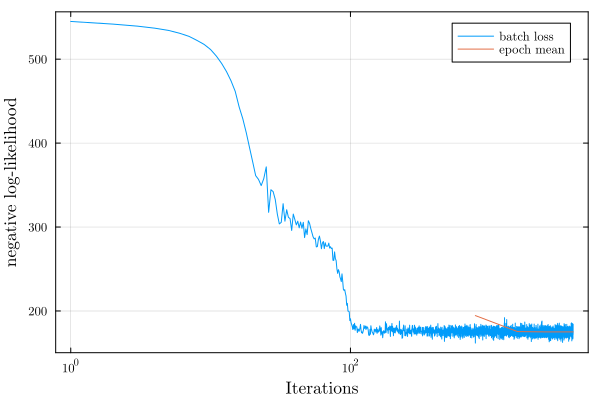

In [14]:
plot_loss(losses_no_dil, length(mnist_binary_loader))

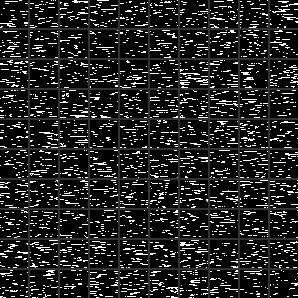

In [15]:
vec2imgs(sample(pix_net_no_dil, 100); nrows=10)

In [16]:
logpdf(pix_net_no_dil, mnist_binary_test |> device; reduction=mean)

-175.03743f0

In [ ]:
begin
    Random.seed!(123)

    pix_net_dil = PixelCNN1D(28^2, n_layers, ks, nc; dilation=true, built_in_padding=false) |> device
    losses_dil, valid_losses_dil, best_pix_net_dil = fit!(pix_net_dil, mnist_binary_loader, Adam(), 8; verbose=true, every_epoch=2, valid_data=mnist_binary_valid)
end;

┌ Info: Epoch 1; Loss = 125.6696
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  25%|██████████▎                              |  ETA: 0:01:08┌ Info: Epoch 3; Loss = 94.1077
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  50%|████████████████████▌                    |  ETA: 0:00:36┌ Info: Epoch 5; Loss = 92.1477
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  75%|██████████████████████████████▊          |  ETA: 0:00:17┌ Info: Epoch 7; Loss = 91.301
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:01:03


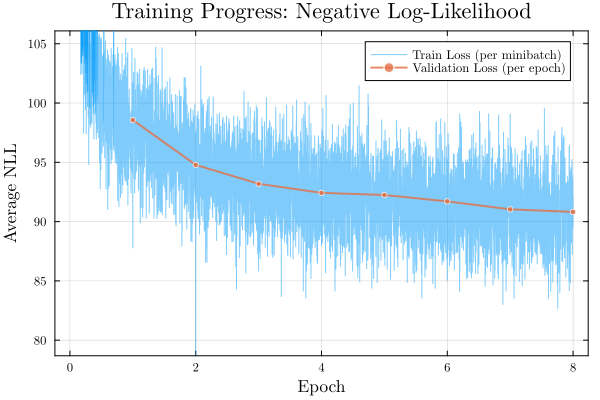

In [18]:
plot_loss_history(losses_dil, valid_losses_dil, mnist_binary_loader)

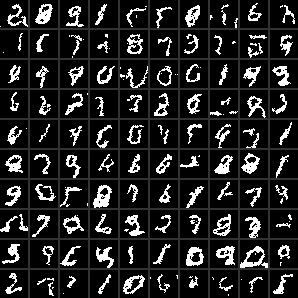

In [19]:
set_rand_seed(1234)
vec2imgs(sample(pix_net_dil, 100); nrows=10)

In [20]:
logpdf(pix_net_dil, mnist_binary_test |> device; reduction=mean)

-90.12419f0

In [ ]:
begin
    Random.seed!(123)

    pix_net_dil_loc_res = PixelCNN1D(28^2, n_layers, ks, nc; res_con=true, dilation=true, add_loc=true, built_in_padding=true) |> device
    losses_dil_loc_res, valid_losses_dil_loc_res, best_pix_net_dil_loc_res = fit!(pix_net_dil_loc_res, mnist_binary_loader,
        Adam(1e-3), 10;
        verbose=true,
        every_epoch=2,
        valid_data=mnist_binary_valid
    )
end;

┌ Info: Epoch 1; Loss = 104.7686
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:01:12┌ Info: Epoch 3; Loss = 92.1574
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:00:48┌ Info: Epoch 5; Loss = 90.4364
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:00:31┌ Info: Epoch 7; Loss = 89.5607
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:15┌ Info: Epoch 9; Loss = 88.9176
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:01:14


In [ ]:
begin
    Random.seed!(123)

    pix_net_dil_loc = PixelCNN1D(28^2, n_layers, ks, nc; dilation=true, add_loc=true) |> device
    losses_dil_loc, valid_losses_dil_loc, best_pix_net_dil_loc = fit!(pix_net_dil_loc, mnist_binary_loader,
        Adam(), 10;
        verbose=true,
        every_epoch=2,
        valid_data=mnist_binary_valid
    )
end;

┌ Info: Epoch 1; Loss = 124.5469
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:00:54┌ Info: Epoch 3; Loss = 92.8699
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:00:41┌ Info: Epoch 5; Loss = 91.3148
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:00:27┌ Info: Epoch 7; Loss = 90.4014
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:14┌ Info: Epoch 9; Loss = 89.7479
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:01:08


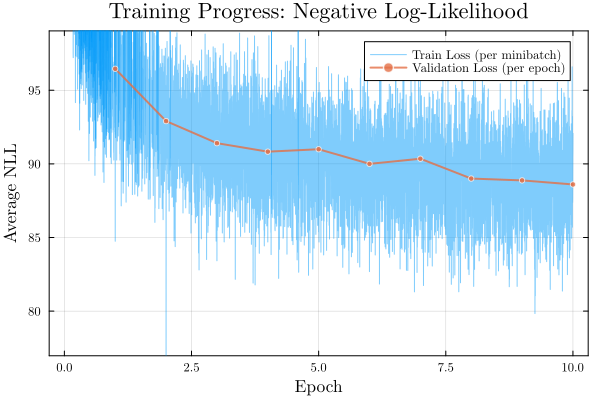

In [23]:
plot_loss_history(losses_dil_loc_res, valid_losses_dil_loc_res, mnist_binary_loader)

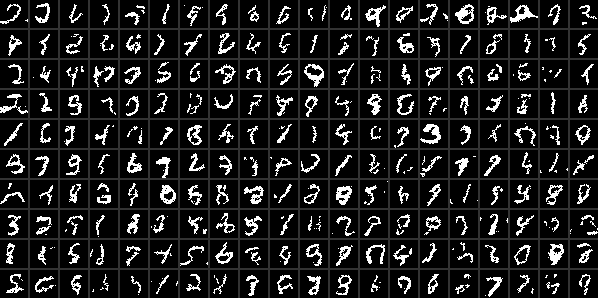

In [24]:
set_rand_seed(1234)
vec2imgs(sample(pix_net_dil_loc, 200); nrows=10)

In [25]:
logpdf(pix_net_dil_loc, mnist_binary_test|>device; reduction=mean)

-88.92272f0

In [26]:
logpdf(pix_net_dil_loc_res, mnist_binary_test|>device; reduction=mean)

-88.11994f0

In [ ]:
begin
    Random.seed!(123)
    wave_net_dil = WaveNet(28^2, n_layers, ks, nc; add_loc=false, dilation=true) |> device
    losses_dil_wn, valid_losses_dil_wn, best_wave_net_dil = fit!(wave_net_dil, mnist_binary_loader,
        Adam(), 10;
        verbose=true, every_epoch=2,
        valid_data=mnist_binary_valid
    )
end

┌ Info: Epoch 1; Loss = 105.4753
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:04:47┌ Info: Epoch 3; Loss = 89.5044
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:02:29┌ Info: Epoch 5; Loss = 87.4854
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:01:25┌ Info: Epoch 7; Loss = 86.5521
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:39┌ Info: Epoch 9; Loss = 86.0005
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:03:03


(Any[519.18f0, 462.81787f0, 408.245f0, 355.99362f0, 314.83884f0, 273.1581f0, 240.36995f0, 227.21593f0, 203.60501f0, 196.69943f0  …  86.55751f0, 89.02745f0, 86.53203f0, 86.7104f0, 84.568405f0, 90.38869f0, 88.09146f0, 81.80609f0, 88.31977f0, 85.58507f0], Any[94.47336f0, 90.59856f0, 88.79504f0, 88.16795f0, 87.4415f0, 86.96659f0, 86.63869f0, 86.56674f0, 86.27815f0, 85.93317f0])

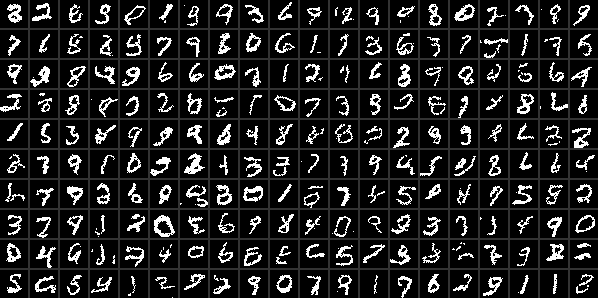

In [28]:
set_rand_seed(1234)
vec2imgs(sample(wave_net_dil, 200); nrows=10)

In [29]:
logpdf(wave_net_dil, mnist_binary_test|> device)

-85.39418f0

In [ ]:
begin
    Random.seed!(123)
    wave_net_dil_loc = WaveNet(28^2, n_layers, ks, nc; add_loc=true, dilation=true) |> device
    losses_dil_loc_wn, valid_losses_dil_loc_wn, best_wave_net_dil_loc = fit!(
        wave_net_dil_loc, mnist_binary_loader,
        Adam(), 10;
        verbose=true,
        every_epoch=2,
        valid_data=mnist_binary_valid
    )
end

┌ Info: Epoch 1; Loss = 105.265
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:01:54┌ Info: Epoch 3; Loss = 89.3232
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:01:25┌ Info: Epoch 5; Loss = 87.2172
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:00:57┌ Info: Epoch 7; Loss = 86.1148
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:28┌ Info: Epoch 9; Loss = 85.5004
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:02:21


(Any[407.2154f0, 338.36185f0, 305.9267f0, 289.43372f0, 296.7735f0, 278.47833f0, 252.61752f0, 239.53001f0, 217.97731f0, 211.30328f0  …  85.86969f0, 88.27579f0, 85.814f0, 85.59326f0, 83.796486f0, 90.44197f0, 87.3649f0, 81.23757f0, 88.07454f0, 83.945465f0], Any[94.0341f0, 90.546585f0, 88.82733f0, 87.95931f0, 87.163765f0, 86.48459f0, 86.1696f0, 86.04038f0, 85.58217f0, 85.58287f0])

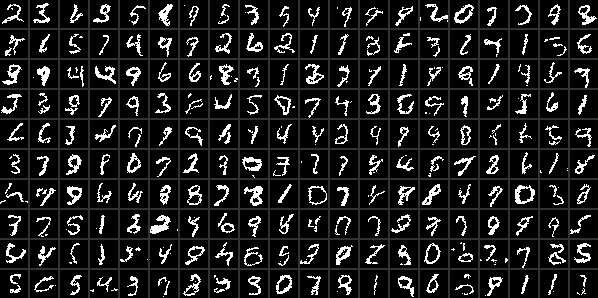

In [31]:
set_rand_seed(1234)
vec2imgs(sample(wave_net_dil_loc, 200); nrows=10)

In [32]:
logpdf(wave_net_dil_loc, mnist_binary_test |> device)

-85.10487f0

In [ ]:
begin
    Random.seed!(123)
    wave_net_dil_loc_skip_fwd = WaveNet(28^2, n_layers, ks, nc; forward_mode=:skip, add_loc=true, dilation=true) |> device
    losses_dil_loc_skipfwd_wn, valid_losses_dil_loc_skipfwd_wn, best_wave_net_dil_loc_skip_fwd = fit!(
        wave_net_dil_loc_skip_fwd, mnist_binary_loader,
        Adam(), 20;
        save_check_points=true,
        verbose=true, every_epoch=4,
        valid_data=mnist_binary_valid
    )
end

Checkpoints will be saved to: checkpoints/WaveNet_forward_mode=skip


┌ Info: Epoch 1; Loss = 109.6865
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:75
Progress:  20%|████████▎                                |  ETA: 0:03:53┌ Info: Epoch 5; Loss = 88.1389
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:75
Progress:  40%|████████████████▍                        |  ETA: 0:02:54┌ Info: Epoch 9; Loss = 86.0803
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:75
Progress:  60%|████████████████████████▋                |  ETA: 0:01:56┌ Info: Epoch 13; Loss = 85.1316
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:75
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:58┌ Info: Epoch 17; Loss = 84.5504
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:75
Progress: 100%|█████████████████████████████████████████| Time: 0:04:49


(Any[558.72656f0, 518.0556f0, 494.65924f0, 471.6267f0, 441.03918f0, 415.4655f0, 386.836f0, 357.9526f0, 334.00107f0, 318.38837f0  …  82.52782f0, 83.55033f0, 86.631134f0, 86.34653f0, 88.27161f0, 79.10292f0, 81.65558f0, 80.201355f0, 87.95995f0, 86.74123f0], Any[95.39047f0, 91.72626f0, 89.61658f0, 88.642525f0, 87.80904f0, 87.315f0, 86.75695f0, 86.28861f0, 86.04112f0, 85.73563f0, 85.44504f0, 85.2703f0, 85.12901f0, 85.044334f0, 85.01562f0, 84.79623f0, 84.73837f0, 84.78339f0, 84.60799f0, 84.55512f0])

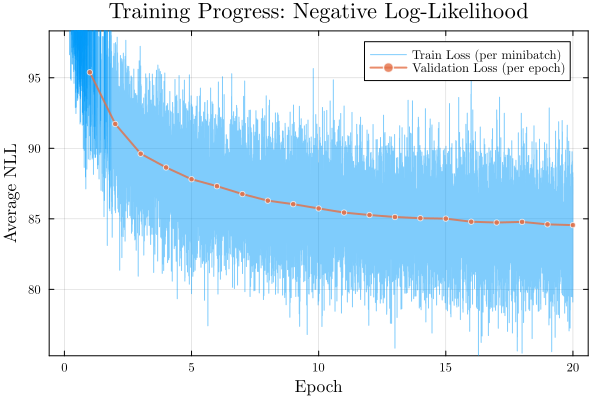

In [87]:
plot_loss_history(losses_dil_loc_skipfwd_wn, valid_losses_dil_loc_skipfwd_wn, mnist_binary_loader)

In [88]:
logpdf(wave_net_dil_loc_skip_fwd, mnist_binary_test |> device)

-84.07469f0

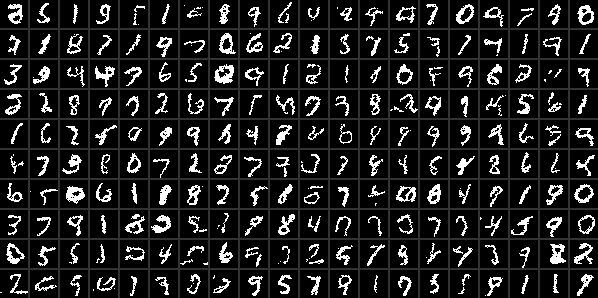

In [89]:
set_rand_seed(1234)
vec2imgs(sample(wave_net_dil_loc_skip_fwd, 200); nrows=10)

In [37]:

"""
    test_autoregressive_property_comprehensive(model; input_shape=(T, C, N), time_dim=1)

Vigorously tests the autoregressive property across EVERY time step in a sequence.
Returns `true` if the model is perfectly causal across all points, or `false` if a leak occurs.
"""
function test_autoregressive_property_comprehensive(model; input_shape=(10, 1, 1), time_dim=1)
    # 1. Generate a dummy input tensor with random floats
    x = rand(Float32, input_shape...)
    T = size(x, time_dim) # Number of time steps

    # 2. Iterate through every single output time step 't_out'
    for t_out in 1:T

        # 3. Compute gradients of the output at step t_out with respect to ALL inputs
        grads = Flux.gradient(x) do input_tensor
            out = model(input_tensor)

            # Isolate the output slice at this specific time step
            out_at_t = selectdim(out, time_dim, t_out)

            # Sum to scalar objective for AD tracking
            return sum(out_at_t)
        end

        # Extract the gradient array back from the gradients tuple
        grad_x = grads[1]

        # 4. Check every input time step 't_in' against our current 't_out'
        for t_in in 1:T
            grad_slice = selectdim(grad_x, time_dim, t_in)
            max_grad = maximum(abs, grad_slice)

            # CRITICAL PROPERTY: If t_in occurs AFTER t_out, the gradient MUST be 0.
            if t_in > t_out
                if max_grad > 1e-7
                    @error "🚨 Future Leakage Found!" t_out t_in max_grad
                    return false
                end
            end
        end
    end

    println("✅ Perfect Causality: Verified across all time steps.")
    return true
end


test_autoregressive_property_comprehensive (generic function with 1 method)

In [38]:
test_autoregressive_property_comprehensive(wave_net_dil_loc |> cpu; input_shape=(28^2, 1, 1))

✅ Perfect Causality: Verified across all time steps.


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 79.5
│   queued_messages = 1
└ @ VSCodeServer.JSONRPC /home/lf28/.vscode-server/extensions/julialang.language-julia-1.249.2/scripts/packages/JSONRPC/src/core.jl:414


true

In [39]:
train_loader, test_loader, valid_loader = load_mnist_data(batch_size; dtype=Bool, tensor_shape=(28*28, 1, :))

(DataLoader(data::Tuple{Array{Float32, 3}, Vector{Int64}}, shuffle=true, batchsize=64), DataLoader(data::Tuple{Array{Float32, 3}, Vector{Int64}}, shuffle=true, batchsize=64), DataLoader(data::Tuple{Array{Float32, 3}, Vector{Int64}}, shuffle=true, batchsize=64))

In [ ]:
begin
    Random.seed!(123)
    wave_net_dil_loc_new_data = WaveNet(28^2, n_layers, ks, nc; add_loc=true, dilation=true) |> device
    losses_dil_loc_wn_new_data, valid_losses_dil_loc_wn_new_data, best_wave_net_dil_loc_new_data = fit!(
        wave_net_dil_loc_new_data, train_loader,
        Adam(), 10;
        verbose=true, every_epoch=2,
        valid_data=valid_loader
    )
end

┌ Info: Epoch 1; Loss = 103.3672
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:02:22┌ Info: Epoch 3; Loss = 88.6283
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:01:44┌ Info: Epoch 5; Loss = 86.6458
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:01:09┌ Info: Epoch 7; Loss = 85.6832
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:34┌ Info: Epoch 9; Loss = 85.1238
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:02:51


(Any[404.49152f0, 333.76898f0, 309.64117f0, 294.41217f0, 293.32095f0, 281.6182f0, 248.0163f0, 226.6651f0, 219.27051f0, 214.60635f0  …  85.87613f0, 80.75088f0, 83.98435f0, 83.71039f0, 81.58466f0, 86.41759f0, 80.80946f0, 84.71268f0, 85.068726f0, 84.54245f0], Any[92.30496f0, 89.13861f0, 87.322914f0, 86.69521f0, 85.861534f0, 85.87516f0, 85.1067f0, 84.93489f0, 84.480675f0, 84.51419f0])

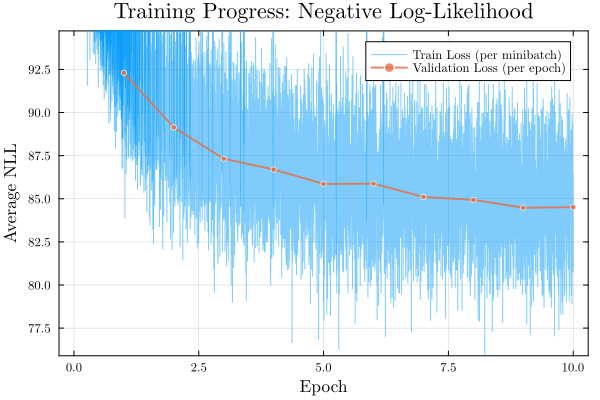

In [41]:
plot_loss_history(losses_dil_loc_wn_new_data, valid_losses_dil_loc_wn_new_data, train_loader)

In [42]:
logpdf(wave_net_dil_loc_new_data, mnist_binary_test |> device), logpdf(wave_net_dil_loc_new_data, test_loader |> device)

(-84.53752f0, -84.34208f0)

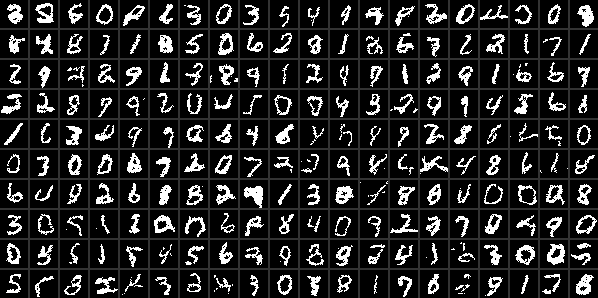

In [43]:
set_rand_seed(1234)
vec2imgs(sample(wave_net_dil_loc_new_data, 200), nrows=10)

In [44]:
begin

    struct ConResWaveNetBlock{T<:ResWaveNetBlock}
        res_block::T
        con_f::Dense
        con_g::Dense
    end

    Flux.@layer ConResWaveNetBlock trainable = (res_block, con_f, con_g)


    function ConResWaveNetBlock(kernel_size::Int=2, dilation::Int=1, ch::Int=32, h_size::Int=5; kwargs...)
        res_block = ResWaveNetBlock(kernel_size, dilation, ch; kwargs...)
        con_f = Dense(h_size=>ch; kwargs...)
        con_g = Dense(h_size=>ch; kwargs...)
        ConResWaveNetBlock(res_block, con_f, con_g)
    end


    function (m::ConResWaveNetBlock)((xs, hs))
        output = m.res_block.causal_con(xs)
        out_f, out_g = Flux.chunk(output, 2, dims=2)
        hf = m.con_f(hs)
        hg = m.con_g(hs)
        output = tanh.(out_f .+ reshape(hf, 1, size(hf)...)) .* σ(out_g .+ reshape(hg, 1, size(hg)...))
        output = m.res_block.res_con(output)
        return xs + output, output
    end
end

In [ ]:
begin

    struct ConWaveNet{T,Y,K}
        d::Int ## number of input; or input dimension
        num_classes::Int
        input_layer::T
        res_blocks::Y
        output_layer::K
        # emb::L
        add_loc::Bool
        dilation::Bool
        forward_mode::Symbol ## forward mode: :chain or :skip
    end

    Flux.@layer ConWaveNet trainable = (input_layer, res_blocks, output_layer)

    function ConWaveNet(d::Int=28^2, num_layers=5, kernel_size::Int=2, nc::Int=32, num_classes::Int=10;
        forward_mode=:chain,
        add_loc=true,
        dilation=true,
        act=relu,
        max_dilation::Int=512,
        kwargs...
    )
        input_layer = Chain(
            LocationInputWrapper(add_loc),
            CausalConv1D(kernel_size, (add_loc ? 2 : 1) => nc,
                identity;
                mask_type=:A,
                res_con=false,
                dilation=1,
                kwargs...)
        )  ## causal mask A
        res_blocks = []
        cap_l = floor(Int, log(kernel_size, max_dilation))
        dils = [2^(l-1) for l in 1:(cap_l+1)]
        for l in 1:num_layers
            dil = dilation ? dils[((l-1)%(length(dils))+1)] : 1 ## exponentially expanding dilation and cycle back 1,2,…,512,1,2,3...
            dil = min(dil, max_dilation)
            push!(res_blocks, ConResWaveNetBlock(kernel_size, dil, nc, num_classes; kwargs...))
        end
        if forward_mode == :chain
            output_layer = Conv((1,), nc => 1; kwargs...)
        else
            out1 = Conv((1,), nc => nc, act; kwargs...)
            out2 = Conv((1,), nc => 1, identity; kwargs...)
            output_layer = Chain(out1, out2)
        end
        # emb = Embedding(num_classes=>emb_size)
        ConWaveNet(d, num_classes, input_layer, Chain(res_blocks...), output_layer, add_loc, dilation, forward_mode)
    end


    function (m::ConWaveNet)((xs, ys))
        outs = m.input_layer(xs)
        hs = Flux.onehotbatch(ys, 0:(m.num_classes-1))
        out1, out2 = m.res_blocks[1]((outs, hs)) ## send both xs and the ys embeddings
        total_skip = out2
        for layer in m.res_blocks[2:end]
            out1, out2 = layer((out1, hs)) ## the condition embeddings are reinforced at this layer
            total_skip += out2
        end

        if m.forward_mode == :chain
            output = m.output_layer(out1)
        else
            # total_skip = relu(total_skip)
            output = m.output_layer(total_skip)
        end
        return output
    end



end

In [46]:
# function fit!(model::ConWaveNet, data_loader, optim=Adam(), max_epochs=10; verbose=true, every_epoch=10)
#     opt = Flux.setup(optim, model)
#     losses = []
#     @showprogress for epoch in 1:max_epochs
#         for xys in data_loader
#             xys = xys |> device
#             li, gs = Flux.withgradient(model) do m
#                 -logpdf(m, xys)
#             end
#             Flux.update!(opt, model, gs[1])
#             push!(losses, li)
#         end
#         if verbose && (epoch % every_epoch) == 1
#             @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
#         end
#     end

#     return losses
# end

In [47]:
function logpdf(model::ConWaveNet, (xs, ys)::Tuple{T,Y}; reduction=mean) where {T<:AbstractArray,Y<:AbstractArray}
    xs_preds = model((xs, ys))
    logL = -Flux.logitbinarycrossentropy(xs_preds[:, 1, :], xs[:, 1, :]; agg=identity)
    logL = sum(logL, dims=1)
    logL |> reduction
end


function logpdf(model::ConWaveNet, data_loader::Union{Flux.DataLoader,DeviceIterator}; reduction=mean)
    logLiks = []
    for (xs, ys) in data_loader
        xs, ys = (xs, ys) 
        logL = logpdf(model, (xs, ys); reduction=identity)[:]
        append!(logLiks, logL)
    end
    return logLiks |> reduction
end

logpdf (generic function with 4 methods)

In [48]:
function sample(model::ConWaveNet, ys, n=1; samples_only=true)
    xs = Array{Float32}(undef, model.d, 1, n) |> device
    probs = similar(xs)
    if ys isa Number
        ys = repeat([ys], n)
    end
    for d in 1:model.d
        ps = σ(model((xs, ys))[d, :, :])
        xs[d, 1, :] = rand_like(ps)[:] .< ps[:]
        probs[d, 1, :] = ps
    end
    if samples_only
        return xs[:, 1, :]
    else
        return xs[:, 1, :], probs[:, 1, :]
    end
end

sample (generic function with 4 methods)

In [61]:
begin
    Random.seed!(123)

    # ConWaveNet()
    con_wnet = ConWaveNet(28^2, n_layers, 2, nc, 10; add_loc=true, dilation=true, act=relu, init=Flux.glorot_uniform) |> device
    losses_con_wnet = fit!(
        con_wnet, train_loader,
        Adam(), 10;
        conditional_model=true,
        verbose=true,
        every_epoch=2
    )

end;

┌ Info: Epoch 1; Loss = 101.0429
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:05:58┌ Info: Epoch 3; Loss = 85.3064
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:03:28┌ Info: Epoch 5; Loss = 83.3297
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:02:05┌ Info: Epoch 7; Loss = 82.2876
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:59┌ Info: Epoch 9; Loss = 81.6498
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:04:47


In [62]:
begin
    Random.seed!(123)

    # ConWaveNet()
    con_wnet_skip = ConWaveNet(28^2, n_layers, 2, nc, 10; forward_mode=:skip, add_loc=true, dilation=true, act=relu, init=Flux.glorot_uniform) |> device
    losses_con_wnet_skip = fit!(
        con_wnet_skip, train_loader,
        Adam(), 10;
        conditional_model=true,
        verbose=true,
        every_epoch=2
    )

end;

┌ Info: Epoch 1; Loss = 108.2457
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  20%|████████▎                                |  ETA: 0:03:56┌ Info: Epoch 3; Loss = 85.9536
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  40%|████████████████▍                        |  ETA: 0:02:46┌ Info: Epoch 5; Loss = 83.6269
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  60%|████████████████████████▋                |  ETA: 0:01:48┌ Info: Epoch 7; Loss = 82.4048
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:53┌ Info: Epoch 9; Loss = 81.7002
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:35
Progress: 100%|█████████████████████████████████████████| Time: 0:04:24


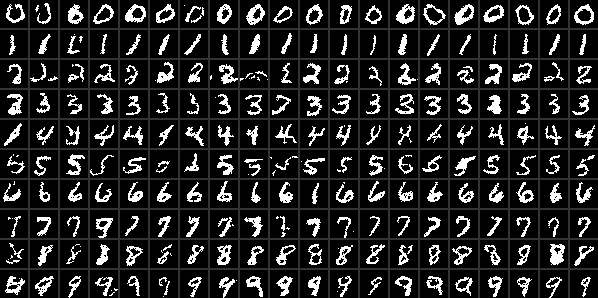

In [63]:
set_rand_seed(1234)
vec2imgs(sample(con_wnet, repeat(0:9, inner=20), 200), nrows=10)

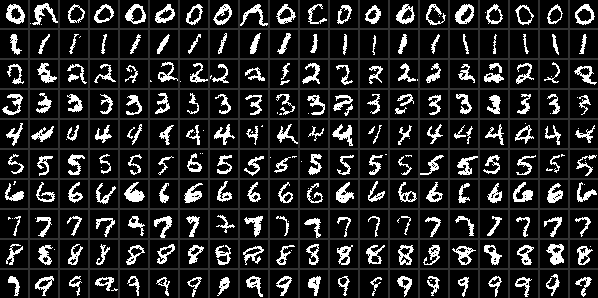

In [64]:
set_rand_seed(1234)
vec2imgs(sample(con_wnet_skip, repeat(0:9, inner=20), 200), nrows=10)

In [65]:
logpdf(con_wnet, test_loader |> device)

-81.28972f0

In [66]:
logpdf(con_wnet_skip, test_loader |> device)

-80.83541f0

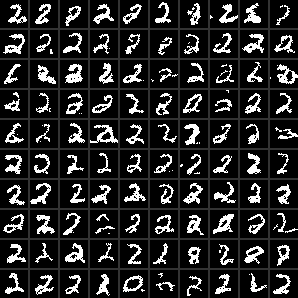

In [67]:
set_rand_seed(1234)
vec2imgs(sample(con_wnet, 2, 100), nrows=10)

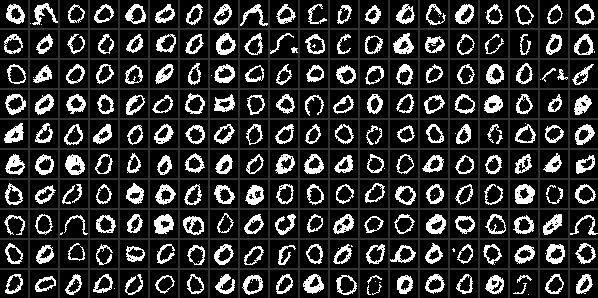

In [68]:
set_rand_seed(1234)
vec2imgs(sample(con_wnet_skip, 0, 200), nrows=10)

In [69]:
function predict_y(model::ConWaveNet, data_loader::Union{Flux.DataLoader, DeviceIterator})
    post_prob = []
    targets = []
    for (xs, ys) in data_loader
        postp = predict_y(model, xs)
        # 2. If postp is on the GPU, download it to CPU so hcat works without errors
        push!(post_prob, xs isa CuArray ? Flux.cpu(postp) : postp)
        # push!(post_prob, postp)
        # 3. CRITICAL FIX: Download ys to the CPU immediately! 
        # This breaks the link to the DeviceIterator's volatile VRAM memory buffer.
        push!(targets, xs isa CuArray ? Flux.cpu(ys) : ys)
    end
    return hcat(post_prob...), targets
end

predict_y (generic function with 2 methods)

In [70]:
function predict_y(model::ConWaveNet, xs::T) where {T<:AbstractArray}
    logliks = []
    for y in 0:(model.num_classes-1)
        ys = fill!(similar(xs, typeof(y), (size(xs)[end],)), y)
        xys = (xs, ys)
        ll = logpdf(model, xys; reduction=identity)
        push!(logliks, ll)
    end
    logliks = vcat(logliks...)
    postp = exp.(logliks .- logsumexp(logliks, dims=1))
        # === CRITICAL FIX ===
    # Force the GPU to finish calculating postp before returning 
    # to the DataLoader loop, preventing early memory freeing.
    # if xs isa CuArray
    #     CUDA.synchronize()
    # end
    return postp
end

predict_y (generic function with 2 methods)

In [71]:
pps, targets = predict_y(con_wnet, test_loader |> device)
mean(argmax.(eachcol(pps |> cpu)) .== vcat(targets...) .+ 1)

0.9715

In [72]:
pps, targets = predict_y(con_wnet_skip, test_loader |> device)
mean(argmax.(eachcol(pps |> cpu)) .== vcat(targets...) .+ 1)

0.975

visualize_all_checkpoints (generic function with 1 method)

Found 21 checkpoints. Rendering plots...


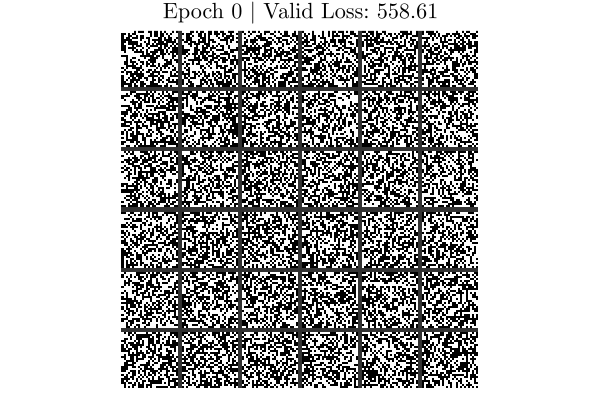

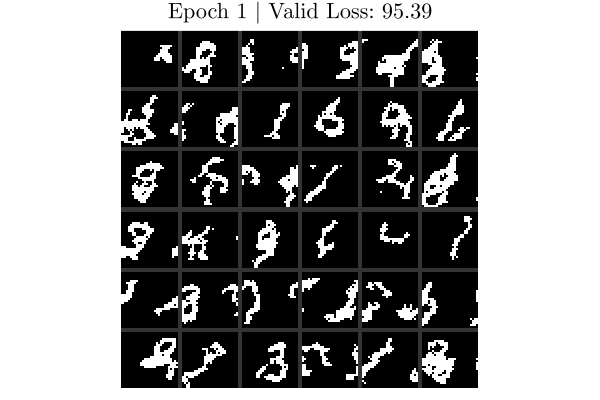

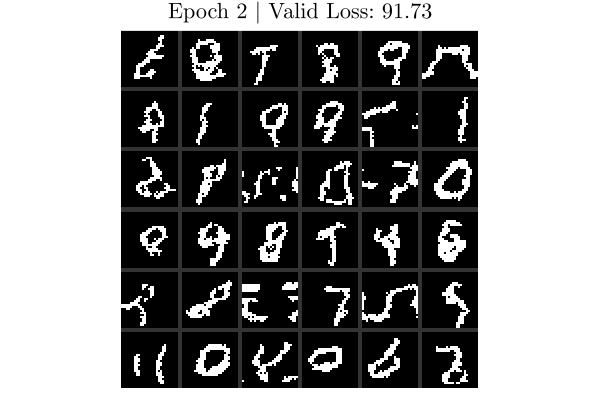

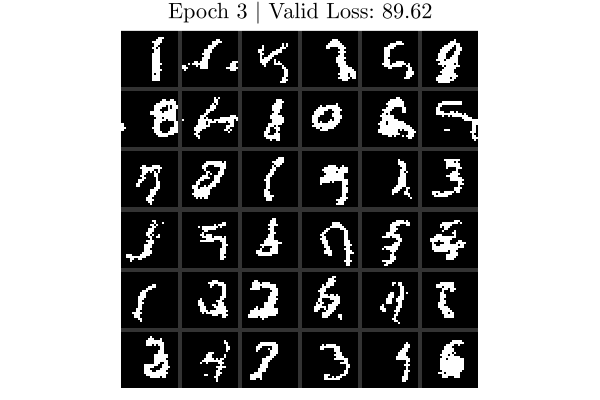

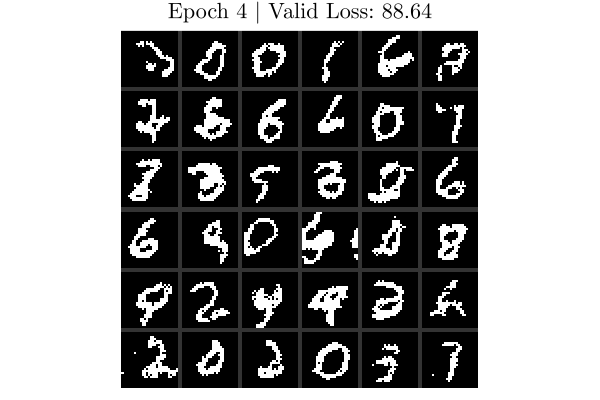

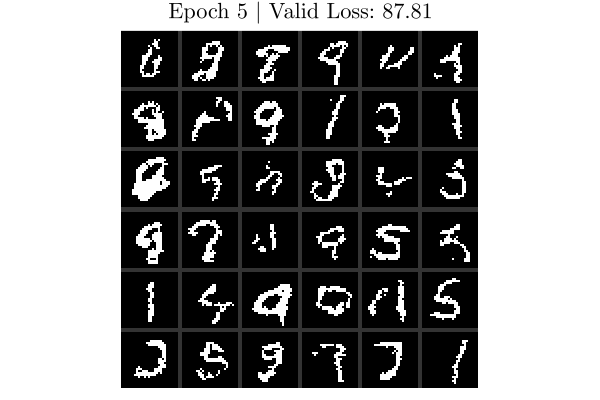

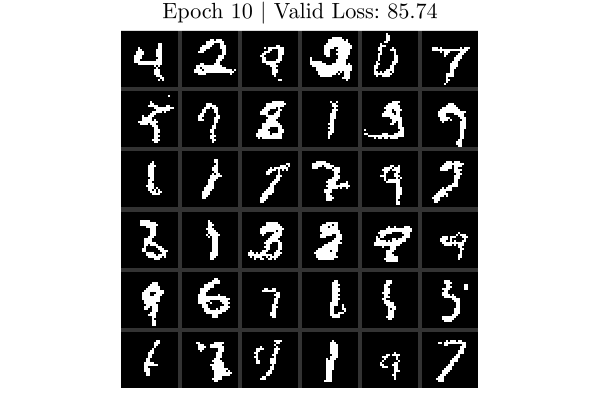

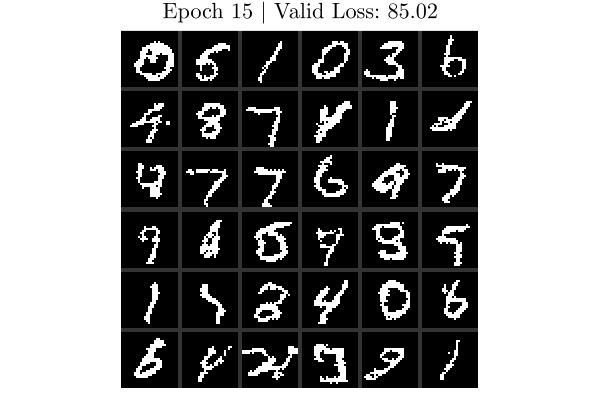

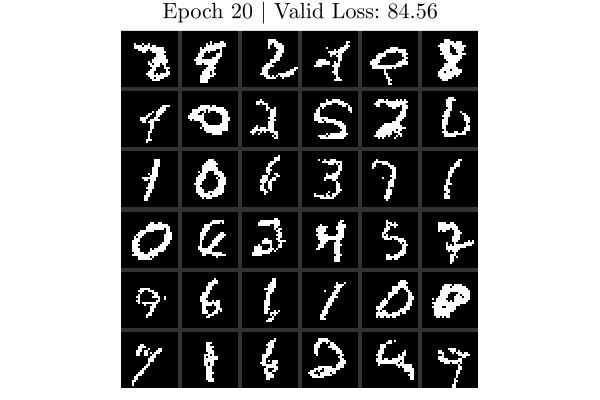

9-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=1}

In [ ]:
folder_path = "./checkpoints/WaveNet_forward_mode=skip"
sample_figs = visualize_all_checkpoints(folder_path; num_samples = 36, nrows = 6);

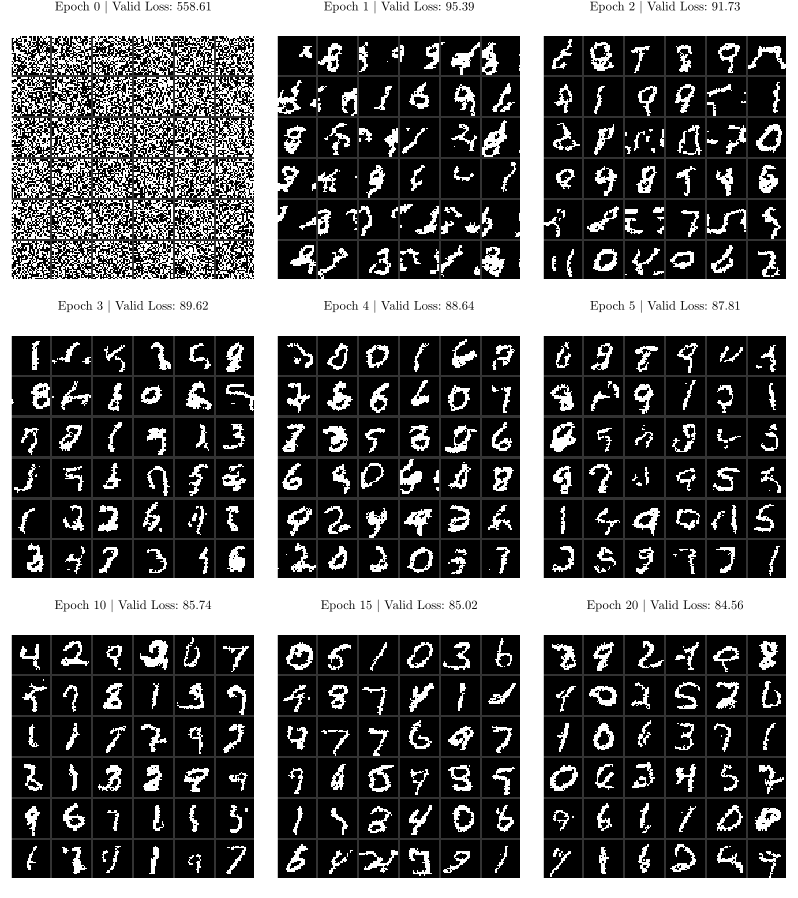

In [137]:
plot(sample_figs..., layout = (3,:), size=(800,900), titlefontsize=8)